#### Teoría de Circuitos II - UTN.BA

# Tarea Semanal 8
#### Autor: Rodríguez Silvosa, Martín
#### Docentes: LLamedo, Mariano ; Moharos, David

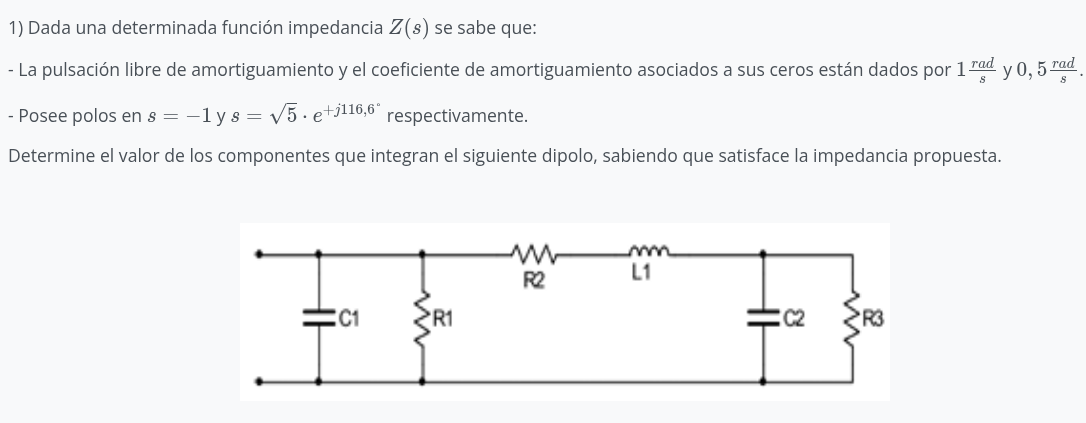
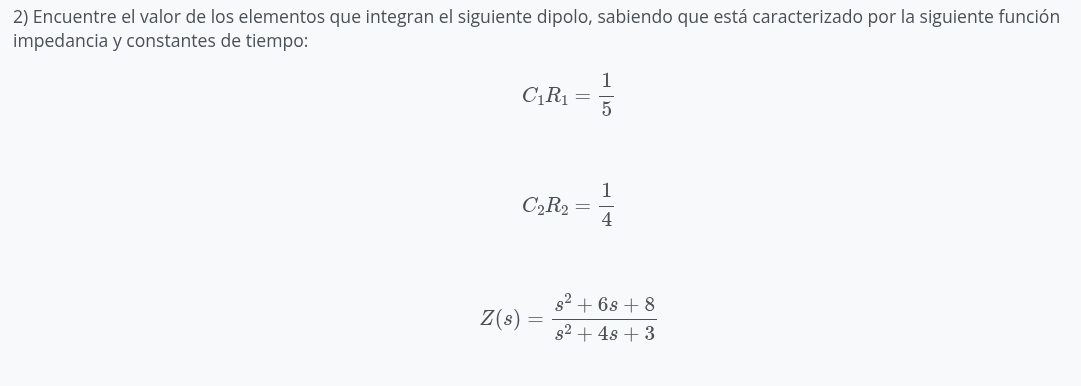
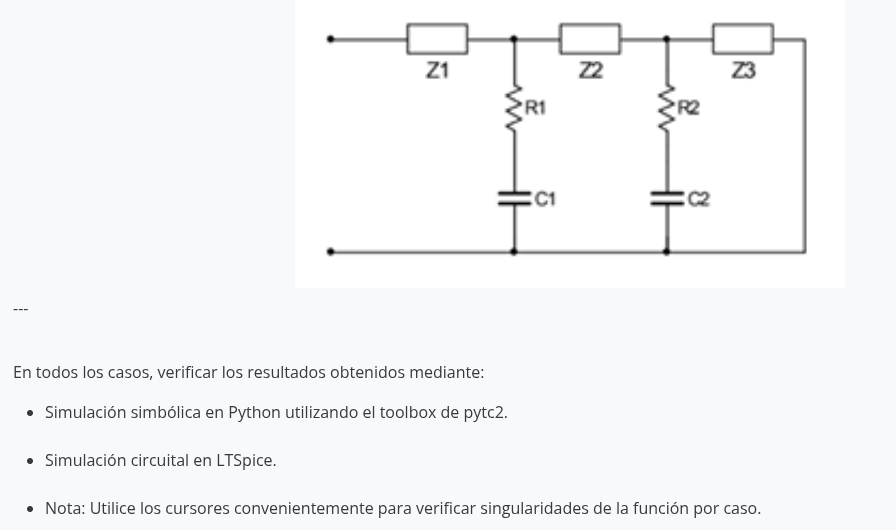

#### Librerías Python:

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from pytc2.general import a_equal_b_latex_s, print_latex, s, symbfunc2tf
from pytc2.sistemas_lineales import bodePlot
from scipy import signal as sig

sp.init_printing()
s = sp.Symbol('s')

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


# Ejercicio 1

## Armado de $Z(s)$:

#### Ceros (par complejo conjugado):
$$
s^2 + 2 \ \xi \ \omega_0 \ s + {\omega_0}^2 = s^2 + 2 \cdot 0,5 \cdot 1 \cdot s + 1 = s^2 + s + 1
$$

#### Polos:
- Polo real: $s = -1 \rightarrow (s+1)$
- Polo complejo: $s = \sqrt{5} \ e^{+j116,6^{\circ}} = \sqrt{5} \ (\cos 116,6^{\circ} + j \ \sin 116,6^{\circ}) = -1 + 2j$. El conjugado $-1-2j$ también será polo:
$$
(s+1-2j)(s+1+2j) = (s+1)^2 + 4 = s^2 + 2s + 5
$$

$$
Z(s) = \ \frac{s^2+s+1}{(s+1)(s^2+2s+5)} = \ \frac{s^2+s+1}{s^3+3s^2+7s+5}
$$

## Topología circuital

El dipolo es una escaleracon $C_1$ y $R_1$ en derivación al principio, luego $R_2$ y $L_1$ en serie, y al final $C_2 \parallel R_3$ en derivación. Me conviene trabajar en admitancia, donde veo directamente:

$$
Y(s) = \frac{1}{Z(s)} = s \ C_1 + G_1 + \frac{1}{R_2 + s \ L_1 + \frac{1}{s \ C_2 + G_3}}
$$

con $G_1 = \frac{1}{R_1}$ y $G_3 = \frac{1}{R_3}$.

Z(s) =


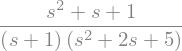

Y(s) = 1/Z(s):


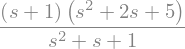

<IPython.core.display.Math object>

In [2]:
num_Z = s**2 + s + 1
den_Z = (s + 1)*(s**2 + 2*s + 5)

Z = num_Z/den_Z

print("Z(s) =")
display(Z)

Y = sp.simplify(1/Z)

print("Y(s) = 1/Z(s):")
display(sp.factor(Y))
print_latex(a_equal_b_latex_s('Y', sp.expand(sp.numer(sp.together(Y)))/sp.expand(sp.denom(sp.together(Y)))))

### Síntesis:

### $C_1$: Remoción polo de $Y$ en infinito
$$
C_1 = K_{\infty} = \lim_{s \rightarrow \infty} \frac{Y(s)}{s}
$$

C1 =


Y1 = Y - C1*s:


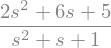

<IPython.core.display.Math object>

In [3]:
### Aprendí que puedo calcular límites :D me ahorra líneas
C1 = sp.limit(Y/s, s, sp.oo)

print("C1 =")
display(C1)

Y1 = sp.simplify(Y - C1*s)
Y1 = sp.factor(sp.together(Y1))

print("Y1 = Y - C1*s:")
display(Y1)
print_latex(a_equal_b_latex_s('Y_1', Y1))

### Capacitor $C_1$ valor $1$;

### $R_1$: conductancia en derivación $G_1$

$G_1$ debe respetar que $\frac{1}{Y_1 - G_1}$ tenga un polo en infinito. Para eso tomo el valor de $Y_1$ en infinito:
$$
G_1 = \lim_{s \rightarrow \infty} Y_1(s)
$$

G1 =


R1 = 1/G1 =


Y2 = Y1 - G1:


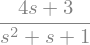

<IPython.core.display.Math object>

In [5]:
G1 = sp.limit(Y1, s, sp.oo)

print("G1 =")
display(G1)
print("R1 = 1/G1 =")
display(1/G1)

Y2 = sp.simplify(Y1 - G1)
Y2 = sp.factor(sp.together(Y2))

print("Y2 = Y1 - G1:")
display(Y2)
print_latex(a_equal_b_latex_s('Y_2', Y2))

### Resistor $R_1$ valor $\frac{1}{2}$;

### $L_1$: polo de $Z_2 = \frac{1}{Y_2}$ en infinito
$$
L_1 = K_{\infty} =  \lim_{s \rightarrow \infty} \frac{Z_2(s)}{s}
$$

Z2 = 1/Y2:


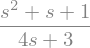

L1 =


Z3 = Z2 - L1*s:


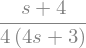

<IPython.core.display.Math object>

In [6]:
Z2 = sp.simplify(1/Y2)

print("Z2 = 1/Y2:")
display(Z2)

L1 = sp.limit(Z2/s, s, sp.oo)

print("L1 =")
display(L1)

Z3 = sp.simplify(Z2 - L1*s)
Z3 = sp.factor(sp.together(Z3))

print("Z3 = Z2 - L1*s:")
display(Z3)
print_latex(a_equal_b_latex_s('Z_3', Z3))

### Inductor $L_1$ valor $\frac{1}{4}$;

### $R_2$: constante de $Z_3$ en infinito
$$
R_2 = \lim_{s \rightarrow \infty} Z_3(s)
$$

R2 =


Z4 = Z3 - R2:


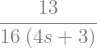

<IPython.core.display.Math object>

In [7]:
R2 = sp.limit(Z3, s, sp.oo)

print("R2 =")
display(R2)

Z4 = sp.simplify(Z3 - R2)
Z4 = sp.factor(sp.together(Z4))

print("Z4 = Z3 - R2:")
display(Z4)
print_latex(a_equal_b_latex_s('Z_4', Z4))

### Resistor $R_2$ valor $\frac{1}{16}$;

### $C_2 \parallel R_3$: lo que me queda último lo paso a admitancia y los valores quedan explícitos:

$$
Y_4(s) = \frac{1}{Z_4(s)} = s \ C_2 + G_3
$$

Y4 = 1/Z4:


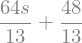

C2 =


G3 =


R3 = 1/G3 =


Resto final Y4 - C2*s - G3 (tiene que ser 0):


In [9]:
Y4 = sp.simplify(1/Z4)
Y4 = sp.expand(Y4)

print("Y4 = 1/Z4:")
display(Y4)

C2 = sp.limit(Y4/s, s, sp.oo)
G3 = sp.simplify(Y4 - C2*s)

print("C2 =")
display(C2)
print("G3 =")
display(G3)
print("R3 = 1/G3 =")
display(1/G3)

print("Resto final Y4 - C2*s - G3 (tiene que ser 0):")
display(sp.simplify(Y4 - C2*s - G3))

### Capacitor $C_2$ valor $\frac{64}{13}$; Resistor $R_3$ valor $\frac{13}{48}$;

## Circuito final, valores:

| Componente | Valor |
|---|---|
| $C_1$ | $1$ |
| $R_1$ | $\frac{1}{2}$ |
| $R_2$ | $\frac{1}{16}$ |
| $L_1$ | $\frac{1}{4}$ |
| $C_2$ | $\frac{64}{13}$ |
| $R_3$ | $\frac{13}{48}$ |

## Verificación simbólica:

Z del circuito sintetizado:


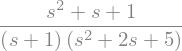

Z_circuito - Z(s) (tiene que ser 0):


In [11]:
R1 = 1/G1
R3 = 1/G3

Z_circuito = 1/(s*C1 + 1/R1 + 1/(R2 + s*L1 + 1/(s*C2 + 1/R3)))

print("Z del circuito sintetizado:")
display(sp.factor(sp.simplify(Z_circuito)))

print("Z_circuito - Z(s) (tiene que ser 0):")
display(sp.simplify(Z_circuito - Z))

## Mapa de polos y ceros:

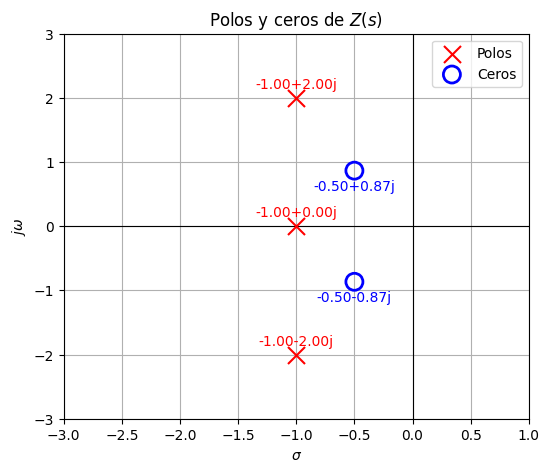

In [43]:
ceros = np.roots([1, 1, 1])
polos = np.roots([1, 3, 7, 5])

fig, ax = plt.subplots(figsize=(6,5))
ax.axhline(0, color='black', linewidth=0.8)
ax.axvline(0, color='black', linewidth=0.8)
ax.scatter(polos.real, polos.imag, marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros.real, ceros.imag, marker='o', facecolors='none', edgecolors='blue', s=150, linewidth=2, label='Ceros', zorder=3)
for p in polos:
    ax.text(p.real, p.imag + 0.15, f'{p.real:.2f}{p.imag:+.2f}j', color='red', ha='center', fontsize=10)
for c in ceros:
    ax.text(c.real, c.imag - 0.3, f'{c.real:.2f}{c.imag:+.2f}j', color='blue', ha='center', fontsize=10)
ax.set_xlabel(r'$\sigma$')
ax.set_ylabel(r'$j\omega$')
ax.set_title("Polos y ceros de $Z(s)$")
ax.set_xlim(-3, 1)
ax.set_ylim(-3, 3)
ax.grid(True)
ax.legend()
plt.show()

## Simulación transferencia pedida VS sintetizada:

### Puntos de verificación:
- Polo en 1: $\omega = 1 rad, 159.155 mHz$
- Par de ceros conjugados: $\omega = \sqrt{0.5² + 0.87²} \approx 1 rad, 159.155 mHz$
- Par de polos conjugados: $\omega = \sqrt{1² + 2²} = \sqrt{5} \approx 2.236 rads, 355.881 mHz$

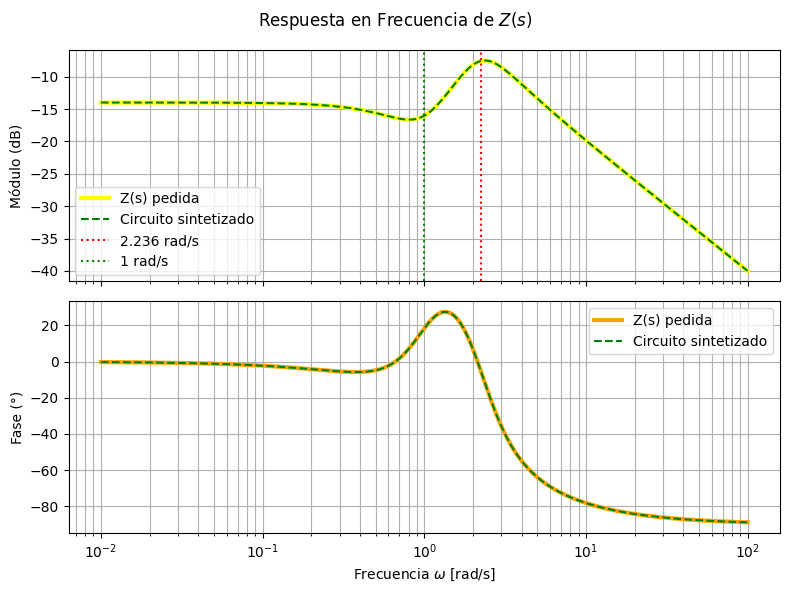

In [19]:
# Transferencia pedida
num = [1, 1, 1]
den = [1, 3, 7, 5]
H = sig.TransferFunction(num, den)

w = np.logspace(-2, 2, 1000)
w_bode, H_mag, H_phase = sig.bode(H, w=w)

# Circuito sintetizado evaluado en s = jw
Z_func = sp.lambdify(s, Z_circuito, 'numpy')
Zc = Z_func(1j*w)
Zc_mag = 20*np.log10(np.abs(Zc))
Zc_phase = np.unwrap(np.angle(Zc))*180/np.pi

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
fig.suptitle("Respuesta en Frecuencia de $Z(s)$")

ax1.semilogx(w_bode, H_mag, color="yellow", lw=3, label="Z(s) pedida")
ax1.semilogx(w, Zc_mag, color="green", lw=1.5, ls="--", label="Circuito sintetizado")
ax1.axvline(2.236, color="red", ls=":", lw=1.5, label="2.236 rad/s")
ax1.axvline(1, color="green", ls=":", lw=1.5, label="1 rad/s")
ax1.set_ylabel("Módulo (dB)")
ax1.grid(True, which="both")
ax1.legend()

ax2.semilogx(w_bode, H_phase, color="orange", lw=3, label="Z(s) pedida")
ax2.semilogx(w, Zc_phase, color="green", lw=1.5, ls="--", label="Circuito sintetizado")
ax2.set_ylabel("Fase (°)")
ax2.set_xlabel(r"Frecuencia $\omega$ [rad/s]")
ax2.grid(True, which="both")
ax2.legend()

plt.tight_layout()
plt.show()

## Simulación en LTSpice:
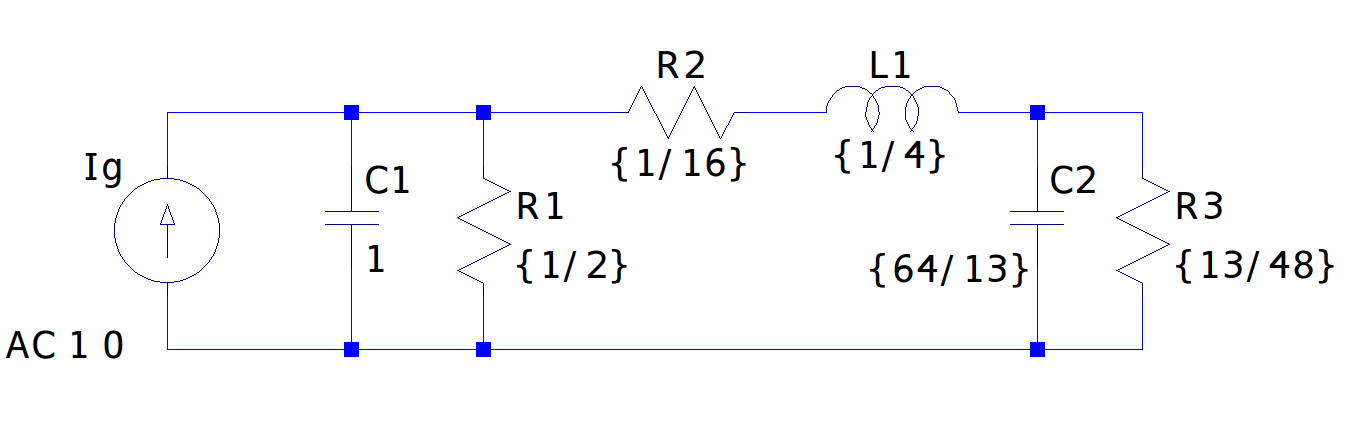
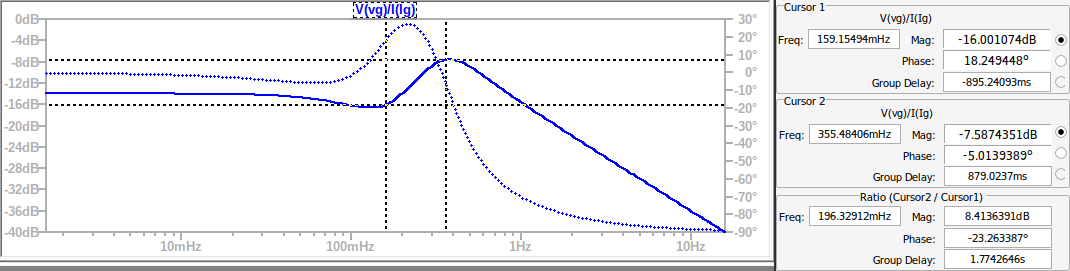

# Ejercicio 2

## Análisis de $Z(s)$

$$
Z(s) = \frac{s^2+6s+8}{s^2+4s+3} = \frac{(s+2)(s+4)}{(s+1)(s+3)}
$$

- Polos: $-1$ y $-3$. Ceros: $-2$ y $-4$.
- Se alternan polo, cero, polo, cero.
- $Z(0) = \frac{8}{3} > Z(\infty) = 1$.

## Topología

$$
Z(s) = Z_1 + \left\{ Z_{s1} \parallel \left[ Z_2 + \left( Z_{s2} \parallel Z_3 \right) \right] \right\}
$$

con las secciones serie RC:
$$
Z_{s1} = R_1 + \frac{1}{s \ C_1} = \frac{1 + s \ R_1 C_1}{s \ C_1} = \frac{s+5}{5 \ s \ C_1} \quad \rightarrow \quad \text{cero en } s=-5
$$
$$
Z_{s2} = R_2 + \frac{1}{s \ C_2} = \frac{1 + s \ R_2 C_2}{s \ C_2} = \frac{s+4}{4 \ s \ C_2} \quad \rightarrow \quad \text{cero en } s=-4
$$

$Z_1$, $Z_2$ y $Z_3$ no tienen constante de tiempo dada en la consigna, por lo que los planteo como resistores.

#### Remoción parcial: en $s=-5$ la rama $Z_{s1}$ es un cortocircuito, $Z(-5) = Z_1$. 
#### Luego remuevo por completo el polo de $Y$ en $-5$ con la rama $R_1 C_1$, y luego repito lo mismo con el cero en $-4$:

Z(s) factorizada:


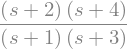

Z(0) = 8/3   Z(oo) = 1
Cero de la rama 1: s = -5    Cero de la rama 2: s = -4


In [21]:
Z = (s**2 + 6*s + 8)/(s**2 + 4*s + 3)

print("Z(s) factorizada:")
display(sp.factor(Z))

print("Z(0) =", Z.subs(s, 0), "  Z(oo) =", sp.limit(Z, s, sp.oo))

tau1 = sp.Rational(1, 5)   # C1*R1
tau2 = sp.Rational(1, 4)   # C2*R2
a1 = 1/tau1                # cero de la rama 1 en s = -a1
a2 = 1/tau2                # cero de la rama 2 en s = -a2
print("Cero de la rama 1: s =", -a1, "   Cero de la rama 2: s =", -a2)

## Gráfico de polos y ceros:

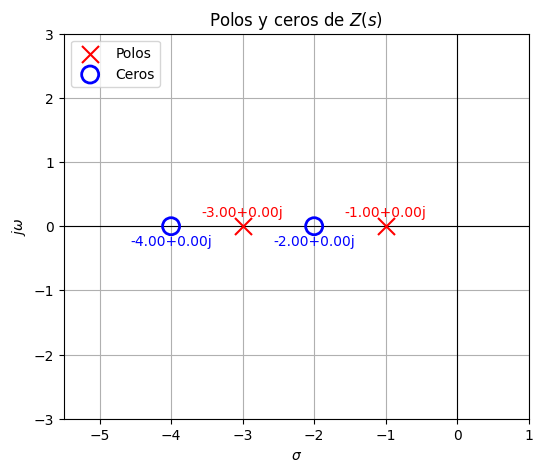

In [46]:
ceros = np.roots([1, 6, 8])
polos = np.roots([1, 4, 3])

fig, ax = plt.subplots(figsize=(6,5))
ax.axhline(0, color='black', linewidth=0.8)
ax.axvline(0, color='black', linewidth=0.8)
ax.scatter(polos.real, polos.imag, marker='x', color='red', s=150, label='Polos', zorder=3)
ax.scatter(ceros.real, ceros.imag, marker='o', facecolors='none', edgecolors='blue', s=150, linewidth=2, label='Ceros', zorder=3)
for p in polos:
    ax.text(p.real, p.imag + 0.15, f'{p.real:.2f}{p.imag:+.2f}j', color='red', ha='center', fontsize=10)
for c in ceros:
    ax.text(c.real, c.imag - 0.3, f'{c.real:.2f}{c.imag:+.2f}j', color='blue', ha='center', fontsize=10)
ax.set_xlabel(r'$\sigma$')
ax.set_ylabel(r'$j\omega$')
ax.set_title("Polos y ceros de $Z(s)$")
ax.set_xlim(-5.5, 1)
ax.set_ylim(-3, 3)
ax.grid(True)
ax.legend()
plt.show()

## Gráfico lineal de polos y ceros:

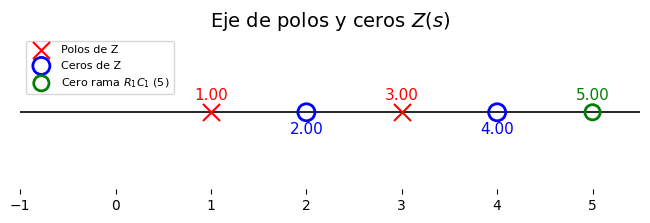

In [36]:
fig, ax = plt.subplots(figsize=(8,2))
ax.axhline(0, color='black', linewidth=1.2)

polos = [1, 3]
ceros = [2, 4]
shunt = [5, 4]

ax.scatter(polos, [0]*len(polos), marker='x', color='red', s=150, label='Polos de Z', zorder=3)
ax.scatter(ceros, [0]*len(ceros), marker='o', facecolors='none', edgecolors='blue', s=150, linewidth=2, label='Ceros de Z', zorder=3)
ax.scatter([5], [0], marker='o', facecolors='none', edgecolors='green', s=120, linewidth=2, label='Cero rama $R_1C_1$ (5)', zorder=3)

for p in polos:
    ax.text(p, 0.06, f'{p:.2f}', color='red', ha='center', va='bottom', fontsize=11)
for c in ceros:
    ax.text(c, -0.06, f'{c:.2f}', color='blue', ha='center', va='top', fontsize=11)
ax.text(5, 0.06, '5.00', color='green', ha='center', va='bottom', fontsize=11)

ax.set_xlim(-1, 5.5)
ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
for sp_ in ['top','right','left','bottom']:
    ax.spines[sp_].set_visible(False)
ax.legend(loc='upper left', fontsize=8)
plt.title("Eje de polos y ceros $Z(s)$", fontsize=14)
plt.show()

## Síntesis:

### $Z_1$: remoción parcial constante en $s = -5$ (cero de la rama $R_1 C_1$)
$$
Z_1 = Z(-5)
$$

Z1 = Z(-5) =


Z' = Z - Z1 :


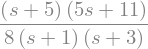

<IPython.core.display.Math object>

In [31]:
Z1 = Z.subs(s, -a1)

print("Z1 = Z(-5) =")
display(Z1)

Zp = sp.factor(sp.together(sp.simplify(Z - Z1)))

print("Z' = Z - Z1 :")
display(Zp)
print_latex(a_equal_b_latex_s("Z'", Zp))

### Resistor $Z_1$ valor $\frac{3}{8}$;

### Rama $R_1 C_1$: remoción total del polo de $Y' = \frac{1}{Z'}$ en $s=-5$

$$
Y_{s1} = \frac{s \ C_1}{1 + s \ R_1 C_1} = \frac{5 \ C_1 \ s}{s + 5}
$$
$$
\text{residuo de } Y_{s1} \text{ en } s=-5: \ -25 \ C_1 \quad \rightarrow \quad C_1 = -\frac{\text{residuo}}{25}, \quad R_1 = \frac{\tau_1}{C_1}
$$

Residuo de Y' en s=-5:


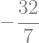

C1 =


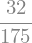

R1 = tau1/C1 =


Y'' = Y' - Ys1 :


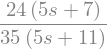

<IPython.core.display.Math object>

In [33]:
Yp = sp.simplify(1/Zp)

res1 = sp.limit(Yp*(s + a1), s, -a1)
C1 = -res1/(a1**2)
R1 = tau1/C1

print("Residuo de Y' en s=-5:")
display(res1)
print("C1 =")
display(C1)
print("R1 = tau1/C1 =")
display(R1)

Ys1 = a1*C1*s/(s + a1)
Ypp = sp.simplify(Yp - Ys1)
Ypp = sp.factor(sp.together(Ypp))

print("Y'' = Y' - Ys1 :")
display(Ypp)
print_latex(a_equal_b_latex_s("Y''", Ypp))

### Capacitor $C_1$ valor $\frac{32}{175}$; Resistor $R_1$ valor $\frac{35}{32}$;

### Pasamos a impedancia: $Z'' = \frac{1}{Y''} = Z_2 + (Z_{s2} \parallel Z_3)$

#### Repito el procedimiento pero esta vez con el cero de la rama 2 en $s=-4$: $Z_2 = Z''(-4)$ :

Z'' = 1/Y'':


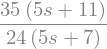

Z2 = Z''(-4) =


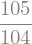

Z''' = Z'' - Z2 :


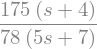

<IPython.core.display.Math object>

In [35]:
Zpp = sp.simplify(1/Ypp)

print("Z'' = 1/Y'':")
display(sp.factor(Zpp))

Z2 = Zpp.subs(s, -a2)

print("Z2 = Z''(-4) =")
display(Z2)

Zppp = sp.factor(sp.together(sp.simplify(Zpp - Z2)))

print("Z''' = Z'' - Z2 :")
display(Zppp)
print_latex(a_equal_b_latex_s("Z'''", Zppp))

### Resistor $Z_2$ valor $\frac{105}{104}$;

### Resistor $Z_3$ y rama $R_2 C_2$ desde $Y''' = \frac{1}{Z'''} = Y_{s2} + \frac{1}{Z_3}$

#### La rama $Y_{s2}$ vale $0$ en $s=0$, entonces:
$$
\frac{1}{Z_3} = Y'''(0)
$$

Y''' = 1/Z''':


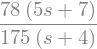

1/Z3 = Y'''(0) = 39/50    ->   Z3 = 50/39
Ys2 = Y''' - 1/Z3 :


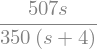

C2 =


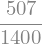

R2 = tau2/C2 =


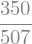

In [38]:
Yppp = sp.simplify(1/Zppp)

G3 = Yppp.subs(s, 0)
Z3 = 1/G3

print("Y''' = 1/Z''':")
display(sp.factor(Yppp))
print("1/Z3 = Y'''(0) =", G3, "   ->   Z3 =", Z3)

Ys2 = sp.factor(sp.together(sp.simplify(Yppp - G3)))

print("Ys2 = Y''' - 1/Z3 :")
display(Ys2)

res2 = sp.limit(Ys2*(s + a2), s, -a2)
C2 = -res2/(a2**2)
R2 = tau2/C2

print("C2 =")
display(C2)
print("R2 = tau2/C2 =")
display(R2)

### Resistor $Z_3$ valor $\frac{50}{39}$; Capacitor $C_2$ valor $\frac{507}{1400}$; Resistor $R_2$ valor $\frac{350}{507}$;

## Circuito final, valores:

| Componente | Valor |
|---|---|
| $Z_1$ | $\frac{3}{8}$ |
| $R_1$ | $\frac{35}{32}$ |
| $C_1$ | $\frac{32}{175}$ |
| $Z_2$ | $\frac{105}{104}$ |
| $R_2$ | $\frac{350}{507}$ |
| $C_2$ | $\frac{507}{1400}$ |
| $Z_3$ | $\frac{50}{39} $ |

Comprobación rápida: $Z(0) = Z_1 + Z_2 + Z_3 = \frac{3}{8}+\frac{105}{104}+\frac{50}{39} = \frac{8}{3}$

## Verificación simbólica:

Z del circuito sintetizado:


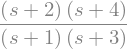

Z_circuito - Z(s) (tiene que ser 0):


C1*R1 = 1/5    C2*R2 = 1/4
Z(0) = Z1+Z2+Z3 = 8/3


In [39]:
# Genero una mini función para dibujar los paralelos:
def par(a, b):
    return a*b/(a + b)

Zs1 = R1 + 1/(s*C1)
Zs2 = R2 + 1/(s*C2)

Z_circuito = Z1 + par(Zs1, Z2 + par(Zs2, Z3))

print("Z del circuito sintetizado:")
display(sp.factor(sp.simplify(Z_circuito)))

print("Z_circuito - Z(s) (tiene que ser 0):")
display(sp.simplify(Z_circuito - Z))

print("C1*R1 =", sp.simplify(C1*R1), "   C2*R2 =", sp.simplify(C2*R2))
print("Z(0) = Z1+Z2+Z3 =", sp.simplify(Z1 + Z2 + Z3))

## Simulación transferencia pedida VS sintetizada:

### Puntos de verificación:
- Z(0) = $\frac{8}{3}$ $\rightarrow$ $\left. Z(0)\right|_{dB} = 20 \cdot log(\frac{8}{3}) = 8.519 dB$
-  Z($\infty$) = $1$ $\rightarrow$ $\left. Z(\infty)\right|_{dB} = 20 \cdot log(1) = 0 dB$ 

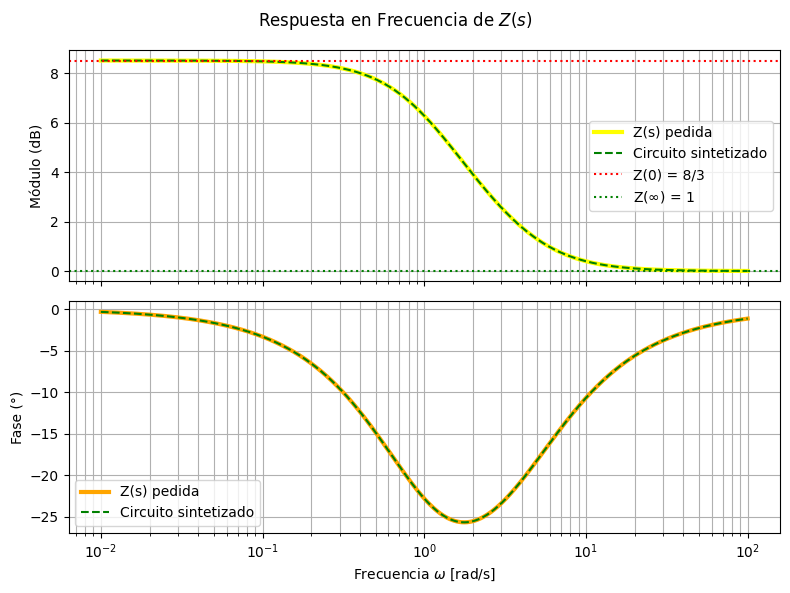

In [48]:
num = [1, 6, 8]
den = [1, 4, 3]
H = sig.TransferFunction(num, den)

w = np.logspace(-2, 2, 1000)
w_bode, H_mag, H_phase = sig.bode(H, w=w)

Z_func = sp.lambdify(s, Z_circuito, 'numpy')
Zc = Z_func(1j*w)
Zc_mag = 20*np.log10(np.abs(Zc))
Zc_phase = np.unwrap(np.angle(Zc))*180/np.pi

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
fig.suptitle("Respuesta en Frecuencia de $Z(s)$")

ax1.semilogx(w_bode, H_mag, color="yellow", lw=3, label="Z(s) pedida")
ax1.semilogx(w, Zc_mag, color="green", lw=1.5, ls="--", label="Circuito sintetizado")
ax1.axhline(8.519, color="red", ls=":", lw=1.5, label="Z(0) = 8/3")
ax1.axhline(0, color="green", ls=":", lw=1.5, label=r"Z($\infty$) = 1")
ax1.set_ylabel("Módulo (dB)")
ax1.grid(True, which="both")
ax1.legend()

ax2.semilogx(w_bode, H_phase, color="orange", lw=3, label="Z(s) pedida")
ax2.semilogx(w, Zc_phase, color="green", lw=1.5, ls="--", label="Circuito sintetizado")
ax2.set_ylabel("Fase (°)")
ax2.set_xlabel(r"Frecuencia $\omega$ [rad/s]")
ax2.grid(True, which="both")
ax2.legend()

plt.tight_layout()
plt.show()

### Simulación LTSpice:
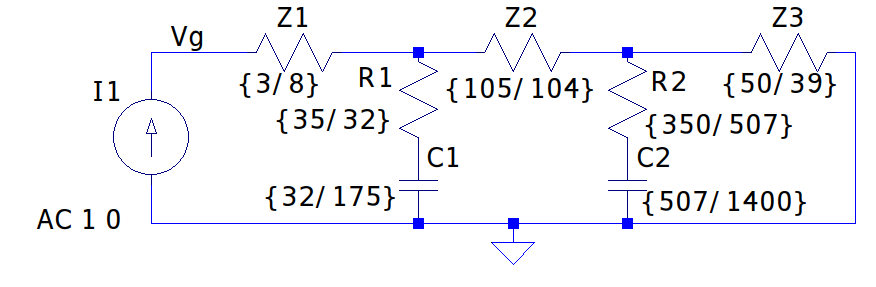
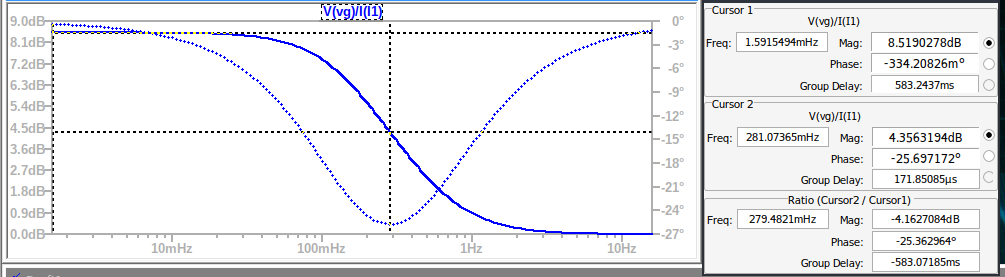

### Las simulaciones verifican el resultado